# Задания 6–7. Признаки SMS и baseline-модель

* **Задание 6** — стратифицированное разбиение 70/15/15 (`random_state=42`), TF-IDF слов и символов, ручные признаки, `Pipeline`.
* **Задание 7** — baseline Logistic Regression, метрики на валидации, разбор ошибок, сохранение и проверка загрузки модели.

Тестовая выборка в этом ноутбуке **не используется**. Код признаков — в `ml/sms_features.py`, модель — в `ml/sms_baseline.py`.

In [1]:
import os, re, sys, json, subprocess
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'manage.py').exists())
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from ml.sms_features import (SmsNormalizer, ManualFeatures, MANUAL_FEATURE_NAMES, load_clean, load_or_create_split,
                             make_matrices, top_terms_by_class, SPLIT_JSON)
FIG = ROOT / 'docs/figures'; FIG.mkdir(parents=True, exist_ok=True)

df = load_clean()
texts = df.text_raw.to_numpy(dtype=object)
labels = df.label.to_numpy()
print('Очищенный набор:', len(df), 'SMS; spam =', int(labels.sum()))

Очищенный набор: 5137 SMS; spam = 620


## Задание 6.1. Стратифицированное разбиение 70/15/15

In [2]:
split = load_or_create_split(labels)      # индексы сохраняются в data/processed/sms_split.json
sizes = pd.DataFrame({k: {'SMS': len(v), 'доля, %': round(len(v) / len(df) * 100, 1),
                          'spam': int(labels[v].sum()), 'доля spam, %': round(labels[v].mean() * 100, 2)}
                      for k, v in split.items()}).T.astype({'SMS': int, 'spam': int})
assert sorted(sum(split.values(), [])) == list(range(len(df)))   # выборки не пересекаются и покрывают весь набор
print('Файл индексов:', SPLIT_JSON.relative_to(ROOT))
sizes

Файл индексов: data\processed\sms_split.json


,SMS,"доля, %",spam,"доля spam, %"
train,3595,70.0,434,12.07
val,771,15.0,93,12.06
test,771,15.0,93,12.06


## Задание 6.2–6.4. TF-IDF слов, символьные N-граммы и ручные признаки в одном `FeatureUnion`

In [3]:
features, X_train, X_val, X_test = make_matrices(texts, split)   # fit — только на train, transform — на val/test
mats = {'X_train': X_train, 'X_val': X_val, 'X_test': X_test}
dims = {k: v.shape for k, v in mats.items()}
for name, mat in mats.items():
    print(f'{name}: {mat.shape[0]} x {mat.shape[1]}, ненулевых элементов: {mat.nnz}, плотность {mat.nnz / (mat.shape[0] * mat.shape[1]):.2%}')
assert X_train.shape[0] == len(split['train']) and X_val.shape[0] == len(split['val']) and X_test.shape[0] == len(split['test'])
assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1]
parts = {n: len(t.steps[-1][1].get_feature_names_out()) if n != 'manual' else len(MANUAL_FEATURE_NAMES) for n, t in features.transformer_list}
print('Столбцов по блокам:', parts)

X_train: 3595 x 35417, ненулевых элементов: 547851, плотность 0.43%
X_val: 771 x 35417, ненулевых элементов: 110801, плотность 0.41%
X_test: 771 x 35417, ненулевых элементов: 113497, плотность 0.42%
Столбцов по блокам: {'word': 9458, 'char': 25953, 'manual': 6}


### Ручные признаки (6 штук) на примерах

In [4]:
demo = ['WINNER!! You have won a £1000 prize. Call 09061701461 now to claim, urgent!!!',
        'Ok, see you at lunch tomorrow',
        'Ваша карта заблокирована! Срочно подтвердите на https://bank-check.example']
manual = ManualFeatures().transform(demo).toarray()
pd.DataFrame(manual, columns=MANUAL_FEATURE_NAMES, index=['spam-пример', 'ham-пример', 'ru-пример']).round(3)

,length,uppercase_ratio,exclamation_count,has_url,has_money,se_groups
spam-пример,77.0,0.190,5.0,0.0,1.0,3.0
ham-пример,29.0,0.043,0.0,0.0,0.0,0.0
ru-пример,74.0,0.032,1.0,1.0,0.0,4.0


### Проверка: векторизатор не видел val/test

In [5]:
word_tfidf = dict(features.transformer_list)['word'].named_steps['tfidf']
tok = lambda s: set(re.findall(r'(?u)\b\w+\b|<\w+>', s))
norm = SmsNormalizer()
train_tokens = set().union(*[tok(s) for s in norm.transform(texts[split['train']])])
eval_tokens = set().union(*[tok(s) for s in norm.transform(texts[split['val'] + split['test']])])
only_eval = sorted(eval_tokens - train_tokens)
leaked = [t for t in only_eval if t in word_tfidf.vocabulary_]
print(f'Слов, которые есть только в val/test: {len(only_eval)}; из них попало в словарь TF-IDF: {len(leaked)}')
assert not leaked

Слов, которые есть только в val/test: 1455; из них попало в словарь TF-IDF: 0


### Топ-15 слов/биграмм с наибольшим средним TF-IDF для каждого класса (по обучающей выборке)

In [6]:
top = top_terms_by_class(features, X_train, labels[split['train']], k=15)
top_df = pd.DataFrame({f'{n}': [f'{t} ({v:.3f})' for t, v in top[c]] for c, n in ((0, 'ham'), (1, 'spam'))}, index=range(1, 16))
top_df

,ham,spam
1,i (0.040),<num> (0.103)
2,you (0.031),<phone> (0.051)
3,to (0.023),to (0.046)
4,<num> (0.021),<money> (0.040)
5,the (0.020),call (0.040)
6,u (0.020),your (0.032)
7,in (0.018),to <num> (0.032)
8,a (0.017),free (0.031)
9,me (0.017),call <phone> (0.030)
10,and (0.017),a (0.029)


### Объяснение: TF-IDF, N-граммы и символьные N-граммы

**TF-IDF** (Term Frequency — Inverse Document Frequency) превращает текст в числовой вектор. TF показывает, как часто слово встречается в самом сообщении (используется `sublinear_tf=True`, то есть 1 + log(tf), чтобы повторы не доминировали). IDF уменьшает вес слов, которые есть почти в каждом сообщении (`you`, `to`, `the`), и увеличивает вес редких различающих слов (`claim`, `prize`). Большое значение признака означает «слово часто в этом сообщении, но редко во всём корпусе». Именно поэтому TF-IDF лучше простого подсчёта слов для задач с шумом из служебной лексики.

**N-граммы слов** `(1, 2)` добавляют к отдельным словам пары соседних слов (`claim prize`, `call <phone>`). Биграмма сохраняет короткий контекст, который теряется при подсчёте слов по отдельности: «free» в «free entry» и «free time» — разные сигналы. Параметр `min_df=2` отбрасывает фразы, встретившиеся один раз (шум и источник переобучения), а `max_df=0.95` — слова, которые есть почти в каждом сообщении.

**Символьные N-граммы** `char_wb` `(3, 5)` — последовательности из 3–5 символов внутри границ слов. Они устойчивы к опечаткам и намеренным искажениям: слова `free` и `fr33` частично совпадают по символьным фрагментам, поэтому модель получает сигнал, даже когда слово написано нестандартно. Этот способ не требует словаря и работает одинаково для латиницы, кириллицы и казахских букв.

**Ручные признаки** (6 штук) добавляют то, чего нет в словах: длину сообщения, долю заглавных букв в исходном тексте, число `!`, наличие `<url>` и `<money>` и число сработавших групп социальной инженерии (срочность, деньги, банк, блокировка, приз, запрос кода, требование перейти по ссылке). Они масштабируются `MaxAbsScaler`, так как длина измеряется сотнями, а TF-IDF лежит в диапазоне [0, 1].

**Защита от утечки.** TF-IDF, словарь и масштабирование — шаги одного `Pipeline`; `fit` вызывается только на обучающей выборке, а на валидации и тесте выполняется `transform`. Поэтому словарь и IDF не «видят» val/test, а сохранённый pipeline содержит всю цепочку преобразований вместе с моделью.

In [7]:
EXPLANATION = '**TF-IDF** (Term Frequency — Inverse Document Frequency) превращает текст в числовой вектор. TF показывает, как часто слово встречается в самом сообщении (используется `sublinear_tf=True`, то есть 1 + log(tf), чтобы повторы не доминировали). IDF уменьшает вес слов, которые есть почти в каждом сообщении (`you`, `to`, `the`), и увеличивает вес редких различающих слов (`claim`, `prize`). Большое значение признака означает «слово часто в этом сообщении, но редко во всём корпусе». Именно поэтому TF-IDF лучше простого подсчёта слов для задач с шумом из служебной лексики.\n\n**N-граммы слов** `(1, 2)` добавляют к отдельным словам пары соседних слов (`claim prize`, `call <phone>`). Биграмма сохраняет короткий контекст, который теряется при подсчёте слов по отдельности: «free» в «free entry» и «free time» — разные сигналы. Параметр `min_df=2` отбрасывает фразы, встретившиеся один раз (шум и источник переобучения), а `max_df=0.95` — слова, которые есть почти в каждом сообщении.\n\n**Символьные N-граммы** `char_wb` `(3, 5)` — последовательности из 3–5 символов внутри границ слов. Они устойчивы к опечаткам и намеренным искажениям: слова `free` и `fr33` частично совпадают по символьным фрагментам, поэтому модель получает сигнал, даже когда слово написано нестандартно. Этот способ не требует словаря и работает одинаково для латиницы, кириллицы и казахских букв.\n\n**Ручные признаки** (6 штук) добавляют то, чего нет в словах: длину сообщения, долю заглавных букв в исходном тексте, число `!`, наличие `<url>` и `<money>` и число сработавших групп социальной инженерии (срочность, деньги, банк, блокировка, приз, запрос кода, требование перейти по ссылке). Они масштабируются `MaxAbsScaler`, так как длина измеряется сотнями, а TF-IDF лежит в диапазоне [0, 1].\n\n**Защита от утечки.** TF-IDF, словарь и масштабирование — шаги одного `Pipeline`; `fit` вызывается только на обучающей выборке, а на валидации и тесте выполняется `transform`. Поэтому словарь и IDF не «видят» val/test, а сохранённый pipeline содержит всю цепочку преобразований вместе с моделью.'

def md_table(df_, index_name=''):
    rows = ['| ' + ' | '.join([index_name] + [str(c) for c in df_.columns]) + ' |', '|' + '---|' * (len(df_.columns) + 1)]
    rows += ['| ' + ' | '.join([str(i)] + [str(v) for v in r]) + ' |' for i, r in zip(df_.index, df_.itertuples(index=False))]
    return '\n'.join(rows)

(ROOT / 'docs/06_TFIDF_FEATURES.md').write_text(
    '# Задание 6. Признаки SMS: TF-IDF, N-граммы, ручные признаки\n\n'
    'Документ создаётся ноутбуком `notebooks/02_sms_features_baseline.ipynb`; код — `ml/sms_features.py`.\n\n'
    '## Разбиение\n\nСтратифицированное 70/15/15, `random_state=42`; индексы сохранены в `data/processed/sms_split.json`.\n\n'
    + md_table(sizes, 'Выборка') + '\n\n'
    '## Состав признаков\n\n'
    '* слова: `TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95, sublinear_tf=True)` — ' + str(parts['word']) + ' столбцов;\n'
    '* символы: `TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, sublinear_tf=True)` — ' + str(parts['char']) + ' столбцов;\n'
    '* ручные признаки (' + str(parts['manual']) + '): ' + ', '.join(MANUAL_FEATURE_NAMES) + '; масштабирование `MaxAbsScaler`.\n\n'
    'Блоки объединены `FeatureUnion` внутри `Pipeline`; `fit` — только на train.\n\n'
    '## Размерности матриц\n\n| Матрица | Строк | Столбцов |\n|---|---:|---:|\n'
    + '\n'.join(f'| {k} | {v[0]} | {v[1]} |' for k, v in dims.items()) + '\n\n'
    f'Проверка отсутствия утечки: из {len(only_eval)} слов, встречающихся только в val/test, в словарь TF-IDF не попало ни одного.\n\n'
    '## Топ-15 слов и биграмм по среднему TF-IDF (train)\n\n' + md_table(top_df, '№') + '\n\n'
    '## Объяснение признаков\n\n' + EXPLANATION + '\n', encoding='utf-8')
print('Записан docs/06_TFIDF_FEATURES.md')

Записан docs/06_TFIDF_FEATURES.md


---
# Задание 7. Baseline: Logistic Regression

## 7.1–7.3. Обучение на train, метрики на validation

Метрики на ВАЛИДАЦИИ (порог 0.50): {'Accuracy': 0.987, 'Precision (spam)': 0.9663, 'Recall (spam)': 0.9247, 'F1 (spam)': 0.9451}
Матрица ошибок [[TN, FP], [FN, TP]]: [[675, 3], [7, 86]]


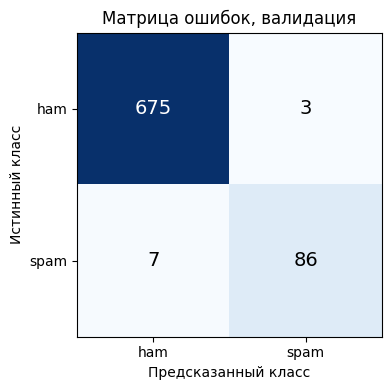

In [8]:
from ml.sms_baseline import build_baseline_pipeline, predict_sms, ARTIFACT, REPORT, THRESHOLD
tr, va = np.array(split['train']), np.array(split['val'])

model = build_baseline_pipeline()                      # LogisticRegression(class_weight='balanced', max_iter=1000)
model.fit(texts[tr], labels[tr])
prob_val = model.predict_proba(texts[va])[:, 1]
pred_val = (prob_val >= THRESHOLD).astype(int)

m = {'Accuracy': accuracy_score(labels[va], pred_val), 'Precision (spam)': precision_score(labels[va], pred_val),
     'Recall (spam)': recall_score(labels[va], pred_val), 'F1 (spam)': f1_score(labels[va], pred_val)}
cm = confusion_matrix(labels[va], pred_val, labels=[0, 1])
print('Метрики на ВАЛИДАЦИИ (порог %.2f):' % THRESHOLD, {k: round(v, 4) for k, v in m.items()})
print('Матрица ошибок [[TN, FP], [FN, TP]]:', cm.tolist())

fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=14, color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax.set_xticks([0, 1], ['ham', 'spam']); ax.set_yticks([0, 1], ['ham', 'spam'])
ax.set_xlabel('Предсказанный класс'); ax.set_ylabel('Истинный класс'); ax.set_title('Матрица ошибок, валидация')
ax.grid(False); fig.tight_layout(); fig.savefig(FIG / 'sms_baseline_confusion.png'); plt.show()

## 7.4. Ошибочно классифицированные сообщения (валидация)

In [9]:
fn = np.where((labels[va] == 1) & (pred_val == 0))[0]
fp = np.where((labels[va] == 0) & (pred_val == 1))[0]
print(f'Всего на валидации: FN = {len(fn)}, FP = {len(fp)}')
rows = [('FN', prob_val[i], texts[va[i]]) for i in fn[np.argsort(prob_val[fn])][:5]]
rows += [('FP', prob_val[i], texts[va[i]]) for i in fp[np.argsort(-prob_val[fp])][:5]]
if len(fp) < 5:      # реальных FP меньше пяти — ошибки не выдумываются, показываются «почти ошибки»
    ok_ham = np.where((labels[va] == 0) & (pred_val == 0))[0]
    rows += [('почти FP', prob_val[i], texts[va[i]]) for i in ok_ham[np.argsort(-prob_val[ok_ham])][:5 - len(fp)]]
errors_df = pd.DataFrame(rows, columns=['тип', 'P(spam)', 'текст'])
errors_df['P(spam)'] = errors_df['P(spam)'].round(3)
pd.set_option('display.max_colwidth', 140)
errors_df

Всего на валидации: FN = 7, FP = 3


,тип,P(spam),текст
0,FN,0.031,"Do you ever notice that when you're driving, anyone going slower than you is an idiot and everyone driving faster than you is a maniac?"
1,FN,0.078,For sale - arsenal dartboard. Good condition but no doubles or trebles!
2,FN,0.131,"Latest News! Police station toilet stolen, cops have nothing to go on!"
3,FN,0.321,"0A$NETWORKS allow companies to bill for SMS, so they are responsible for their ""suppliers"", just as a shop has to give a guarantee on wh..."
4,FN,0.416,"SMS. ac JSco: Energy is high, but u may not know where 2channel it. 2day ur leadership skills r strong. Psychic? Reply ANS w/question. E..."
5,FP,0.751,Your bill at 3 is £33.65 so thats not bad!
6,FP,0.588,NEFT Transaction with reference number &lt;#&gt; for Rs. &lt;DECIMAL&gt; has been credited to the beneficiary account on &lt;#&gt; ...
7,FP,0.530,How to Make a girl Happy? It's not at all difficult to make girls happy. U only need to be... 1. A friend 2. Companion 3. Lover 4. Chef ...
8,почти FP,0.408,"""CHA QUITEAMUZING THATSCOOL BABE,PROBPOP IN & CU SATTHEN HUNNY 4BREKKIE! LOVE JEN XXX. PSXTRA LRG PORTIONS 4 ME PLEASE """
9,почти FP,0.398,WE REGRET TO INFORM U THAT THE NHS HAS MADE A MISTAKE.U WERE NEVER ACTUALLY BORN.PLEASE REPORT 2 YOR LOCAL HOSPITAL 2B TERMINATED.WE R S...


**Разбор причин** (гипотезы по содержанию сообщений, а не результат анализа вкладов признаков):

* **FN (пропущенный спам)** — это рекламные и «развлекательные» рассылки без типичных маркеров: нет ссылки, номера, суммы и слов-призывов
  (`free`, `claim`, `call`), поэтому по лексике они не отличаются от личной переписки. Одно сообщение (гороскоп с «Reply») лежит
  у порога — вероятность 0,42.
* **FP (ложная тревога)** — легитимные сообщения, которые содержат сильные спам-признаки: сумма в фунтах (`<money>`),
  служебное банковское уведомление с числовыми заполнителями, цепочка с множеством `<#>`. Это ожидаемый компромисс при `class_weight='balanced'`.
* Реальных FP на валидации меньше пяти, поэтому недостающие позиции дополнены «почти ошибками» — верно классифицированными ham
  с наибольшей вероятностью спама. Они явно помечены и **не** выдаются за ошибки.

## 7.5. Сохранение pipeline

In [10]:
ARTIFACT.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(model, ARTIFACT)
print('Сохранено:', ARTIFACT.relative_to(ROOT), f'({ARTIFACT.stat().st_size / 1024:.0f} КБ)')

Сохранено: ml\artifacts\sms_baseline.joblib (939 КБ)


Загрузка сохранённой модели **в отдельной ячейке** и сравнение предсказаний:

In [11]:
loaded = joblib.load(ARTIFACT)
prob_loaded = loaded.predict_proba(texts[va])[:, 1]
print('Предсказания совпадают:', bool(np.allclose(prob_loaded, prob_val)), '| макс. расхождение:', float(np.abs(prob_loaded - prob_val).max()))
assert np.allclose(prob_loaded, prob_val)

check = subprocess.run([sys.executable, '-c', 'from ml.sms_baseline import predict_sms; print(predict_sms("Ok, see you at lunch tomorrow"))'],
                       cwd=ROOT, capture_output=True, text=True)
print('Загрузка в НОВОМ процессе Python:', 'успешно' if check.returncode == 0 else 'ОШИБКА', check.stdout.strip() or check.stderr[-200:])
assert check.returncode == 0

Предсказания совпадают: True | макс. расхождение: 0.0


Загрузка в НОВОМ процессе Python: успешно {'label': 0, 'probability': 0.020862041665585272}


## 7.6. Функция `predict_sms(text) -> dict` на новых текстах

In [12]:
for t in ['WINNER!! You have won a £1000 prize. Call 09061701461 now to claim',
          'Ok, see you at lunch tomorrow',
          'Free entry! Text WIN to 80086 to receive your reward',
          'Ваша карта заблокирована! Срочно сообщите код']:
    print(predict_sms(t), '<-', t)

{'label': 1, 'probability': 0.9985509832531316} <- WINNER!! You have won a £1000 prize. Call 09061701461 now to claim
{'label': 0, 'probability': 0.020862041665585272} <- Ok, see you at lunch tomorrow
{'label': 1, 'probability': 0.9332091406896115} <- Free entry! Text WIN to 80086 to receive your reward
{'label': 1, 'probability': 0.5197724430982134} <- Ваша карта заблокирована! Срочно сообщите код


Для русского и казахского текстов оценка **ненадёжна**: модель обучена на английском наборе (см. ограничения в паспорте набора).

In [13]:
fmt = lambda x: f'{x:.4f}'
saved = json.loads(REPORT.read_text(encoding='utf-8'))
assert saved['validation']['confusion_matrix'] == cm.tolist(), 'отчёт ml/artifacts/sms_baseline_report.json расходится с ноутбуком'

def comment_for(text):
    return next((v for k, v in COMMENTS.items() if text.startswith(k)), 'Комментарий не подготовлен')

COMMENTS = {'Do you ever notice that when you': 'Рекламная рассылка в форме шутки-наблюдения: нет ссылки, номера, суммы и слов-призывов, по лексике это обычная разговорная фраза (p ≈ 0,03).', 'For sale - arsenal dartboard': 'Короткое объявление о продаже без номера и цены; по стилю неотличимо от личного сообщения.', 'Latest News! Police station toilet': 'Новостная шутка с подпиской; единственный заметный маркер — «!», этого недостаточно.', '0A$NETWORKS allow companies': 'Информационный/жалобный текст без типичной спам-лексики; название сети записано с искажением и словам модели не знакомо.', 'SMS. ac JSco: Energy is high': 'Платный гороскоп с призывом «Reply»; много сокращений (u, 2day, r); вероятность 0,42 близка к порогу 0,5 — пограничный случай.', 'Your bill at 3 is': 'Личное сообщение с суммой в фунтах. Гипотеза: признак `<money>` у спама встречается в ≈31% сообщений против ≈0,2% у ham, поэтому сам факт суммы сильно повышает вероятность.', 'NEFT Transaction with reference': 'Служебное банковское уведомление с заполнителями (`<#>`, `<DECIMAL>`, `<TIME>`); по форме похоже на автоматическую рассылку, которых в spam много.', 'How to Make a girl Happy': 'Длинное цепочное сообщение с десятками числовых заполнителей `<#>` (после нормализации — `<num>`); `<num>` встречается в ≈88% спама и в ≈19% ham.', '"CHA QUITEAMUZING': 'Верно классифицировано как ham, но высокая доля заглавных букв и «!» подняли вероятность до 0,41.', 'WE REGRET TO INFORM U': 'Шуточное сообщение капсом в стиле официального уведомления; верно ham, вероятность 0,40.'}
err_lines = '\n'.join(
    f"| {r.тип} | {r._2:.3f} | {r.текст[:110].replace('|', '/')}{'…' if len(r.текст) > 110 else ''} | {comment_for(r.текст)} |"
    for r in errors_df.itertuples())

(ROOT / 'docs/07_BASELINE_REPORT.md').write_text(
    '# Задание 7. Baseline: Logistic Regression\n\n'
    'Документ создаётся ноутбуком `notebooks/02_sms_features_baseline.ipynb`; код — `ml/sms_baseline.py`. '
    'Обучение — на train (' + str(len(tr)) + ' SMS), метрики — на validation (' + str(len(va)) + ' SMS). '
    '**Тестовая выборка не использовалась.** Модель: `LogisticRegression(class_weight="balanced", max_iter=1000)` '
    'в одном `Pipeline` с признаками задания 6; порог 0,50. Артефакт: `ml/artifacts/sms_baseline.joblib`.\n\n'
    '## Метрики на валидации (класс «мошенничество» = spam)\n\n'
    '| Accuracy | Precision | Recall | F1 |\n|---:|---:|---:|---:|\n'
    f"| {fmt(m['Accuracy'])} | {fmt(m['Precision (spam)'])} | {fmt(m['Recall (spam)'])} | {fmt(m['F1 (spam)'])} |\n\n"
    '## Матрица ошибок (абсолютные числа)\n\n| | предсказано ham | предсказано spam |\n|---|---:|---:|\n'
    f'| **истинно ham** | TN = {cm[0,0]} | FP = {cm[0,1]} |\n| **истинно spam** | FN = {cm[1,0]} | TP = {cm[1,1]} |\n\n'
    'График: `docs/figures/sms_baseline_confusion.png`.\n\n'
    '## Разбор ошибок\n\n'
    f'На валидации {len(fn)} FN и {len(fp)} FP. Показаны 5 FN и ' + (f'{len(fp)} FP + {5 - len(fp)} «почти FP»' if len(fp) < 5 else '5 FP') + '. '
    'Реальные ошибки не выдумываются: «почти FP» — верно классифицированные ham с наибольшей вероятностью спама, они помечены отдельно. '
    'Причины — гипотезы по содержанию, а не результат анализа вкладов признаков.\n\n'
    '| Тип | P(spam) | Сообщение | Возможная причина |\n|---|---:|---|---|\n' + err_lines + '\n\n'
    '## Проверка сохранения и загрузки\n\n'
    '* pipeline сохранён в `ml/artifacts/sms_baseline.joblib`, загружен в отдельной ячейке: предсказания на валидации совпадают;\n'
    '* артефакт загружается и в новом процессе Python (классы преобразователей находятся в `ml/sms_features.py`, а не в `__main__`);\n'
    '* `predict_sms(text) -> {"label", "probability"}` использует сохранённый pipeline; нормализация `normalize_sms` выполняется внутри него.\n\n'
    '## Ограничения\n\nМодель обучена на англоязычном наборе UCI SMS Spam Collection; спам в нём не тождествен финансовому мошенничеству. '
    'Для русского и казахского языков оценка ненадёжна. Требования раздела 3.4 к итоговой модели относятся к заданию 8; здесь это baseline.\n',
    encoding='utf-8')
print('Записан docs/07_BASELINE_REPORT.md')

Записан docs/07_BASELINE_REPORT.md
